# Guía de laboratorio 08 — FFT, polinomios y transformadas sobre campos finitos
**UNSAAC · Algoritmos Avanzados · 2026-II · Grupo 5**

**Integrantes:** Choquenaira Quispe, Noe Franklin (133962); Porroa Sivana, Yeni Ruth (120893); Quispe Rimachi, Romario (164257); Yaranga Achahui, Aldo (103179).

**Cuaderno autónomo:** ejecute **todas las celdas desde el inicio** en Google Colab o Jupyter con Python 3.11+. Cada ejercicio calcula y muestra su resultado debajo. **No usa `%%writefile`, archivos locales del repositorio, directorios temporales ni subprocesos.** Las funciones, pruebas automatizadas, tablas HTML, datasets CSV en memoria y gráficos vectoriales SVG interactivos permanecen en memoria y se visualizan directamente debajo de cada celda.

## 1. Preparación del entorno y visualización en memoria
Configuración del kernel, importaciones de la biblioteca estándar de Python y utilidades para renderizado de tablas HTML (`show_table`), ejecución de pruebas unitarias (`run_tests`) y generación de gráficos vectoriales SVG en memoria (`line_chart`), sin requerir librerías externas ni archivos locales.

In [1]:
import csv
import io
import json
import math
from random import Random
import unittest
from cmath import exp, pi
from dataclasses import dataclass
from html import escape
from statistics import median
from time import perf_counter_ns
from zipfile import ZipFile, ZIP_DEFLATED
from base64 import b64encode
from IPython.display import HTML, SVG, display
import sys

if sys.version_info < (3, 11):
    raise RuntimeError("Se requiere Python 3.11 o posterior")

DATASETS = {}       # Filas CSV en memoria: nunca se depende de archivos en disco.
CHARTS = {}         # SVG vectoriales en memoria: cada figura aparece debajo de su celda.

def show_table(rows, columns=None, limit=20, title=None):
    rows = list(rows)
    if not rows:
        print("Tabla vacía")
        return
    columns = columns or list(rows[0])
    header = "".join(f"<th>{escape(str(k))}</th>" for k in columns)
    body = "".join(
        "<tr>" + "".join(f"<td>{escape(str(row.get(k, '')))}</td>" for k in columns) + "</tr>"
        for row in rows[:limit]
    )
    caption = f"<b>{escape(title)}</b><br>" if title else ""
    display(HTML(caption + '<div style="overflow-x:auto;max-height:430px;overflow-y:auto">'
                 '<table style="border-collapse:collapse;font-size:13px" border="1" cellpadding="5">'
                 f"<thead><tr>{header}</tr></thead><tbody>{body}</tbody></table></div>"))
    if len(rows) > limit:
        print(f"Se muestran {limit} de {len(rows)} filas; el conjunto completo queda en memoria.")

def run_tests(*classes):
    suite = unittest.TestSuite(unittest.defaultTestLoader.loadTestsFromTestCase(cls)
                               for cls in classes)
    output = io.StringIO()
    result = unittest.TextTestRunner(stream=output, verbosity=1).run(suite)
    print(output.getvalue().strip())
    assert result.wasSuccessful(), "Fallaron pruebas; revise la salida anterior"

print(f"Entorno listo: Python {sys.version.split()[0]}; sin módulos ni archivos auxiliares.")

Entorno listo: Python 3.12.8; sin módulos ni archivos auxiliares.


## 8. Ejercicios resueltos: funciones y salidas junto a cada caso

### 8.1 Ejercicio resuelto 1: Convolución directa (oráculo cuadrático)
Multiplicación polinomial mediante doble bucle $c_k = \sum_{i+j=k} a_i b_j$ de complejidad $\Theta(mn)$. Para $A(x) = 1 + 2x + 3x^2$ y $B(x) = 4 + 5x$, el producto esperado es $[4, 13, 22, 15]$.

In [2]:
@dataclass
class OperationCounts:
    butterflies: int = 0
    multiplications: int = 0
    additions: int = 0
    stages: int = 0

def naive_convolution(a, b, *, stats=None):
    """Convolución lineal exacta para enteros; [] si una entrada está vacía."""
    if not a or not b:
        return []
    result = [0] * (len(a) + len(b) - 1)
    for i, ai in enumerate(a):
        for j, bj in enumerate(b):
            result[i + j] += ai * bj
            if stats is not None:
                stats.multiplications += 1
                stats.additions += 1
    return result

print("Directa [1,2,3] * [4,5]:", naive_convolution([1, 2, 3], [4, 5]))

Directa [1,2,3] * [4,5]: [4, 13, 22, 15]


In [3]:
def resuelto_1():
    """Multiplicación directa de [1,2,3] y [4,5]."""
    a, b = [1, 2, 3], [4, 5]
    result = naive_convolution(a, b)
    assert result == [4, 13, 22, 15]
    return {"a": str(a), "b": str(b), "c": str(result)}

show_table([resuelto_1()], title="Ejercicio resuelto 1: Convolución directa")

a,b,c
"[1, 2, 3]","[4, 5]","[4, 13, 22, 15]"


### 8.2 Ejercicio resuelto 2: FFT, IFFT y multiplicación de polinomios
Evaluación sobre raíces complejas de la unidad y algoritmo divide y vencerás de Cooley–Tukey.

In [4]:
def _check_length(n):
    if n < 1 or n & (n - 1):
        raise ValueError("La longitud debe ser una potencia de dos positiva")

def _butterfly(stats):
    if stats is not None:
        stats.butterflies += 1
        stats.multiplications += 2
        stats.additions += 2

def fft(values, *, stats=None):
    """DFT recursiva de signo +, radix-2; no modifica values."""
    n = len(values)
    _check_length(n)
    if stats is not None:
        stats.stages += n.bit_length() - 1

    def transform(a):
        size = len(a)
        if size == 1:
            return [complex(a[0])]
        even = transform(a[::2])
        odd = transform(a[1::2])
        root = exp(2j * pi / size)
        w = 1 + 0j
        result = [0j] * size
        for k in range(size // 2):
            t = w * odd[k]
            result[k] = even[k] + t
            result[k + size // 2] = even[k] - t
            w *= root
            _butterfly(stats)
        return result

    return transform(values)

def ifft(values, *, stats=None):
    """DFT inversa, conjugación y normalización por N."""
    _check_length(len(values))
    transformed = fft([complex(z).conjugate() for z in values], stats=stats)
    if stats is not None:
        stats.multiplications += len(values)
    return [z.conjugate() / len(values) for z in transformed]

padded = [1, 2, 3, 0]
f_val = fft(padded)
roundtrip = ifft(f_val)
max_err = max(abs(x - y) for x, y in zip(padded, roundtrip))
print("FFT([1,2,3,0]):", [f"{z.real:+.2f}{z.imag:+.2f}j" for z in f_val])
print(f"Error máximo roundtrip IFFT(FFT): {max_err:.2e}")

FFT([1,2,3,0]): ['+6.00+0.00j', '-2.00+2.00j', '+2.00+0.00j', '-2.00-2.00j']
Error máximo roundtrip IFFT(FFT): 5.72e-18


In [5]:
def next_power_of_two(value):
    if type(value) is not int:
        raise TypeError("value debe ser entero")
    if value < 1:
        raise ValueError("value debe ser positivo")
    return 1 << (value - 1).bit_length()

def convolution_fft_raw(a, b, *, method="recursive", stats=None):
    if method not in ("recursive", "iterative"):
        raise ValueError("method debe ser 'recursive' o 'iterative'")
    if not a or not b:
        return []
    length = len(a) + len(b) - 1
    n = next_power_of_two(length)
    pa = list(a) + [0] * (n - len(a))
    pb = list(b) + [0] * (n - len(b))
    if method == "recursive":
        fa, fb = fft(pa, stats=stats), fft(pb, stats=stats)
    else:
        fa = fft_iterative(pa, stats=stats)
        fb = fft_iterative(pb, stats=stats)
    fc = [x * y for x, y in zip(fa, fb)]
    if stats is not None:
        stats.multiplications += n
    if method == "recursive":
        return ifft(fc, stats=stats)[:length]
    return fft_iterative(fc, invert=True, stats=stats)[:length]

def multiply_fft(a, b, tolerance=1e-7, *, method="recursive", stats=None):
    values = convolution_fft_raw(a, b, method=method, stats=stats)
    result = []
    for z in values:
        rounded = round(z.real)
        if abs(z.imag) > tolerance or abs(z.real - rounded) > tolerance:
            raise ArithmeticError("Error FFT superior a la tolerancia")
        result.append(rounded)
    return result

def resuelto_2():
    a, b = [1, 2, 3], [4, 5]
    padded = a + [0]
    roundtrip = ifft(fft(padded))
    result = multiply_fft(a, b)
    assert result == [4, 13, 22, 15]
    assert max(abs(x - y) for x, y in zip(padded, roundtrip)) < 1e-7
    err_imag = max(abs(z.imag) for z in convolution_fft_raw(a, b))
    return {
        "fft": str([f"{z.real:.1f}+{z.imag:.1f}j" for z in fft(padded)]),
        "producto": str(result),
        "error_imaginario": f"{err_imag:.2e}"
    }

show_table([resuelto_2()], title="Ejercicio resuelto 2: FFT, IFFT y multiplicación")

fft,producto,error_imaginario
"['6.0+0.0j', '-2.0+2.0j', '2.0+0.0j', '-2.0+-2.0j']","[4, 13, 22, 15]",6.66e-16


### 8.3 Ejercicio resuelto 3: NTT e INTT en $\mathbb{F}_{17}$
Cálculo de la Transformada Teórica de Números en el campo primo $\mathbb{F}_{17}$ con la raíz $\omega=4$ de orden multiplicativo 4.

In [6]:
def ntt_direct(values, root, modulus):
    """Oráculo cuadrático: evaluación de la definición de NTT, no benchmark."""
    n = len(values)
    return [sum(value * pow(root, j * k, modulus)
                for j, value in enumerate(values)) % modulus for k in range(n)]

def intt_direct(values, root, modulus):
    """NTT directa con raíz inversa y escala N^{-1} (oráculo)."""
    n = len(values)
    transformed = ntt_direct(values, pow(root, -1, modulus), modulus)
    return [x * pow(n, -1, modulus) % modulus for x in transformed]

vec = [1, 2, 3, 4]
ntt_res = ntt_direct(vec, 4, 17)
intt_res = intt_direct(ntt_res, 4, 17)
print(f"NTT_17([1,2,3,4], w=4): {ntt_res}")
print(f"INTT_17(espectro): {intt_res}")

NTT_17([1,2,3,4], w=4): [10, 7, 15, 6]
INTT_17(espectro): [1, 2, 3, 4]


In [7]:
def resuelto_3():
    a = [1, 2, 3, 4]
    transformed = ntt_direct(a, 4, 17)
    recovered = intt_direct(transformed, 4, 17)
    assert transformed == [10, 7, 15, 6] and recovered == a
    return {
        "entrada": str(a),
        "raiz": 4,
        "modulo": 17,
        "ntt": str(transformed),
        "intt": str(recovered)
    }

show_table([resuelto_3()], title="Ejercicio resuelto 3: NTT e INTT en F17")

entrada,raiz,modulo,ntt,intt
"[1, 2, 3, 4]",4,17,"[10, 7, 15, 6]","[1, 2, 3, 4]"


## 9.1 Biblioteca modular transforms.py (Propuesto 1)
Implementación integral de FFT iterativa *in-place* con inversión de bits, validación rigurosa de raíces y generadores modulares, y NTT radix-2 cuasilineal.

### Inversión de bits y FFT iterativa in-place
Reordena las hojas del árbol divide y vencerás en tiempo $O(N)$ y memoria auxiliar $O(1)$, evitando llamadas recursivas y optimizando la localidad espacial.

In [8]:
def _bit_reverse(values):
    n = len(values)
    j = 0
    for i in range(1, n):
        bit = n >> 1
        while j & bit:
            j ^= bit
            bit >>= 1
        j ^= bit
        if i < j:
            values[i], values[j] = values[j], values[i]

def fft_iterative(values, *, invert=False, stats=None):
    """FFT radix-2 iterativa in-place; modifica una lista de N valores."""
    if not isinstance(values, list):
        raise TypeError("La FFT iterativa requiere una lista mutable")
    n = len(values)
    _check_length(n)
    _bit_reverse(values)
    size = 2
    while size <= n:
        root = exp((-2j if invert else 2j) * pi / size)
        for start in range(0, n, size):
            w = 1 + 0j
            for k in range(size // 2):
                u = values[start + k]
                t = w * values[start + k + size // 2]
                values[start + k] = u + t
                values[start + k + size // 2] = u - t
                w *= root
                _butterfly(stats)
        if stats is not None:
            stats.stages += 1
        size <<= 1
    if invert:
        for i in range(n):
            values[i] /= n
        if stats is not None:
            stats.multiplications += n
    return values

test_arr = [1, 2, 3, 4, 0, -2, 1, 0]
rec_out = fft(test_arr)
iter_out = fft_iterative(test_arr.copy())
print("Diferencia máxima FFT recursiva vs iterativa:", max(abs(x - y) for x, y in zip(rec_out, iter_out)))

Diferencia máxima FFT recursiva vs iterativa: 0.0


### Aritmética modular, validación de raíces y NTT radix-2
Comprueba que el módulo sea primo, que $N \mid (p-1)$, y que la raíz posea orden multiplicativo exactamente igual a $N$.

In [9]:
def _prime(modulus):
    if type(modulus) is not int or modulus < 2:
        return False
    if modulus == 2:
        return True
    if modulus % 2 == 0:
        return False
    return all(modulus % d for d in range(3, math.isqrt(modulus) + 1, 2))

def modular_inverse(a, modulus):
    if type(a) is not int or type(modulus) is not int:
        raise TypeError("Se requieren enteros")
    if modulus < 2 or math.gcd(a, modulus) != 1:
        raise ValueError("El inverso modular no existe")
    return pow(a, -1, modulus)

def validate_root(root, length, modulus):
    if type(root) is not int or type(length) is not int or type(modulus) is not int:
        raise TypeError("Raíz, longitud y módulo deben ser enteros")
    _check_length(length)
    if not _prime(modulus):
        raise ValueError("El módulo debe ser primo")
    if (modulus - 1) % length:
        raise ValueError("N debe dividir p-1")
    root %= modulus
    if pow(root, length, modulus) != 1 or (
        length > 1 and pow(root, length // 2, modulus) == 1
    ):
        raise ValueError("La raíz no tiene orden exacto N")
    return True

def _prime_factors(value):
    factors = set()
    divisor = 2
    while divisor * divisor <= value:
        if value % divisor == 0:
            factors.add(divisor)
            while value % divisor == 0:
                value //= divisor
        divisor += 1 if divisor == 2 else 2
    if value > 1:
        factors.add(value)
    return factors

def _validate_generator(generator, modulus):
    if type(generator) is not int:
        raise TypeError("primitive_root debe ser entero")
    if not _prime(modulus):
        raise ValueError("El módulo debe ser primo")
    if generator % modulus == 0 or any(
        pow(generator, (modulus - 1) // factor, modulus) == 1
        for factor in _prime_factors(modulus - 1)
    ):
        raise ValueError("primitive_root debe generar F_p^*")

def ntt(values, invert, modulus, root, *, stats=None):
    """NTT/INTT radix-2, sin mutar entrada; root tiene orden len(values)."""
    n = len(values)
    validate_root(root, n, modulus)
    data = [x % modulus for x in values]
    _bit_reverse(data)
    if invert:
        root = modular_inverse(root % modulus, modulus)
    size = 2
    while size <= n:
        step = pow(root, n // size, modulus)
        for start in range(0, n, size):
            w = 1
            for k in range(size // 2):
                u = data[start + k]
                t = w * data[start + k + size // 2] % modulus
                data[start + k] = (u + t) % modulus
                data[start + k + size // 2] = (u - t) % modulus
                w = w * step % modulus
                _butterfly(stats)
        if stats is not None:
            stats.stages += 1
        size <<= 1
    if invert:
        inverse_n = modular_inverse(n, modulus)
        data = [x * inverse_n % modulus for x in data]
        if stats is not None:
            stats.multiplications += n
    return data

def multiply_ntt(a, b, modulus, primitive_root, *, stats=None):
    """Convolución lineal exacta MODULO p."""
    _validate_generator(primitive_root, modulus)
    if not a or not b:
        return []
    length = len(a) + len(b) - 1
    n = next_power_of_two(length)
    if (modulus - 1) % n:
        raise ValueError("El módulo no permite la longitud N requerida")
    root = pow(primitive_root, (modulus - 1) // n, modulus)
    validate_root(root, n, modulus)
    pa = list(a) + [0] * (n - len(a))
    pb = list(b) + [0] * (n - len(b))
    fa = ntt(pa, False, modulus, root, stats=stats)
    fb = ntt(pb, False, modulus, root, stats=stats)
    pointwise = [x * y % modulus for x, y in zip(fa, fb)]
    if stats is not None:
        stats.multiplications += n
    return ntt(pointwise, True, modulus, root, stats=stats)[:length]

MODULUS = 998244353
PRIMITIVE_ROOT = 3
print("NTT radix-2 módulo 17:", ntt([1, 2, 3, 4], False, 17, 4))
print("Multiply NTT módulo 17 ([1,2,3]*[4,5]):", multiply_ntt([1, 2, 3], [4, 5], 17, 3))

NTT radix-2 módulo 17: [10, 7, 15, 6]
Multiply NTT módulo 17 ([1,2,3]*[4,5]): [4, 13, 5, 15]


### Pruebas unitarias: Convolución directa y casos extremos

In [10]:
MANUAL_CASES = (
    ([], [1, 2], []),
    ([0], [0], [0]),
    ([3], [-2], [-6]),
    ([1, 2, 3], [4, 5], [4, 13, 22, 15]),
    ([1, -1], [1, 1], [1, 0, -1]),
    ([1, 0, 0, 1], [1, 1], [1, 1, 0, 1, 1]),
)

class TestConvolution(unittest.TestCase):
    def test_casos_manuales(self):
        for a, b, expected in MANUAL_CASES:
            with self.subTest(a=a, b=b):
                self.assertEqual(naive_convolution(a, b), expected)
                self.assertEqual(multiply_fft(a, b), expected)
                self.assertEqual(multiply_fft(a, b, method="iterative"), expected)
                self.assertEqual(multiply_ntt(a, b, 17, 3), [x % 17 for x in expected])

    def test_vacios_y_cero_conservan_longitud(self):
        self.assertEqual(naive_convolution([], [0]), [])
        self.assertEqual(multiply_fft([], [0]), [])
        self.assertEqual(multiply_ntt([], [0], 17, 3), [])
        self.assertEqual(multiply_fft([0, 0], [0, 0, 0]), [0] * 4)

    def test_potencia_minima(self):
        self.assertEqual([next_power_of_two(i) for i in (1, 2, 3, 4, 5, 8, 9)],
                         [1, 2, 4, 4, 8, 8, 16])

run_tests(TestConvolution)

...
----------------------------------------------------------------------
Ran 3 tests in 0.003s

OK


### Pruebas unitarias: FFT compleja, tolerancias e inversión in-place

In [11]:
class TestFFT(unittest.TestCase):
    def test_roundtrip_potencias(self):
        for n in (1, 2, 4, 8, 16):
            a = [x * x - 3 for x in range(n)]
            with self.subTest(n=n):
                self.assertTrue(all(abs(x - y) < 1e-8 for x, y in zip(a, ifft(fft(a)))))

    def test_iterativa_inplace_y_orden(self):
        a = [1, 2, 3, 4, 0, -2, 1, 0]
        expected = fft(a)
        b = a.copy()
        self.assertIs(fft_iterative(b), b)
        self.assertTrue(all(abs(x - y) < 1e-8 for x, y in zip(b, expected)))
        fft_iterative(b, invert=True)
        self.assertTrue(all(abs(x - y) < 1e-8 for x, y in zip(b, a)))

    def test_rechazo_longitudes_invalidas(self):
        for a in ([], [1, 2, 3]):
            with self.assertRaises(ValueError):
                fft(a)
            with self.assertRaises(ValueError):
                ifft(a)
            with self.assertRaises(ValueError):
                fft_iterative(a)

    def test_padding_evita_circularidad(self):
        self.assertEqual(multiply_fft([1, 0, 0, 1], [1, 1]), [1, 1, 0, 1, 1])

run_tests(TestFFT)

....
----------------------------------------------------------------------
Ran 4 tests in 0.002s

OK


### Pruebas unitarias: NTT modular y validación de raíces exactas

In [12]:
class TestNTT(unittest.TestCase):
    def test_modulo_17_resuelto3(self):
        a = [1, 2, 3, 4]
        transformed = ntt(a, False, 17, 4)
        self.assertEqual(transformed, [10, 7, 15, 6])
        recovered = ntt(transformed, True, 17, 4)
        self.assertEqual(recovered, a)

    def test_validacion_raices(self):
        self.assertTrue(validate_root(1, 1, 17))
        self.assertTrue(validate_root(16, 2, 17))
        self.assertTrue(validate_root(4, 4, 17))
        self.assertTrue(validate_root(13, 4, 17))
        with self.assertRaises(ValueError):
            validate_root(4, 8, 17)
        with self.assertRaises(ValueError):
            validate_root(1, 4, 17)

    def test_modulo_998244353_roundtrip(self):
        for n in (1, 2, 4, 8, 16, 32):
            root = pow(PRIMITIVE_ROOT, (MODULUS - 1) // n, MODULUS)
            a = [(i * 37 + 11) % MODULUS for i in range(n)]
            with self.subTest(n=n):
                self.assertEqual(ntt(ntt(a, False, MODULUS, root), True, MODULUS, root), a)

run_tests(TestNTT)

...
----------------------------------------------------------------------
Ran 3 tests in 0.033s

OK


### Pruebas diferenciales: FFT vs NTT vs Convolución Directa

In [13]:
class TestMultiplication(unittest.TestCase):
    def test_comparacion_diferencial_aleatorios(self):
        rng = Random(42)
        for n in (4, 8, 16):
            a = [rng.randint(-50, 50) for _ in range(n)]
            b = [rng.randint(-50, 50) for _ in range(n)]
            direct = naive_convolution(a, b)
            by_fft_rec = multiply_fft(a, b, method="recursive")
            by_fft_iter = multiply_fft(a, b, method="iterative")
            by_ntt = multiply_ntt(a, b, MODULUS, PRIMITIVE_ROOT)
            self.assertEqual(direct, by_fft_rec)
            self.assertEqual(direct, by_fft_iter)
            self.assertEqual([x % MODULUS for x in direct], by_ntt)

run_tests(TestMultiplication)

.
----------------------------------------------------------------------
Ran 1 test in 0.041s

OK


## 9.2 Pruebas diferenciales y análisis experimental (Propuesto 2)

### Escenario A: Casos manuales, raíces válidas y validación diferencial

In [14]:
def polynomial_pair(size, seed, bounds=(-10, 10)):
    rng = Random(seed)
    return ([rng.randint(*bounds) for _ in range(size)],
            [rng.randint(*bounds) for _ in range(size)])

def manual_and_roots():
    manual = []
    for i, (a, b, expected) in enumerate(MANUAL_CASES):
        actual = naive_convolution(a, b)
        by_fft = multiply_fft(a, b)
        by_ntt = multiply_ntt(a, b, 17, 3)
        assert actual == expected == by_fft
        assert by_ntt == [x % 17 for x in expected]
        manual.append({"caso": i, "a": str(a), "b": str(b),
                       "esperado": str(expected), "directa": str(actual),
                       "fft": str(by_fft), "ntt_mod_17": str(by_ntt)})
    DATASETS["casos_manuales.csv"] = manual

    roots = []
    for p, generator, max_n in ((17, 3, 16), (MODULUS, PRIMITIVE_ROOT, 1 << 23)):
        n = 1
        while n <= max_n:
            root = pow(generator, (p - 1) // n, p)
            assert validate_root(root, n, p)
            roots.append({"modulo": p, "generador": generator, "n": n,
                          "raiz_orden_n": root, "orden": n,
                          "valida": True, "n_maxima": max_n})
            n *= 2
    DATASETS["modulos_raices.csv"] = roots
    return manual, roots

manual, roots = manual_and_roots()
show_table(manual, title="Casos manuales y oráculos de referencia")
show_table([r for r in roots if r["n"] in (1, 2, 4, 8, 16, 32768, 1 << 23)],
           title="Primos, generadores y raíces NTT seleccionadas")

caso,a,b,esperado,directa,fft,ntt_mod_17
0,[],"[1, 2]",[],[],[],[]
1,[0],[0],[0],[0],[0],[0]
2,[3],[-2],[-6],[-6],[-6],[11]
3,"[1, 2, 3]","[4, 5]","[4, 13, 22, 15]","[4, 13, 22, 15]","[4, 13, 22, 15]","[4, 13, 5, 15]"
4,"[1, -1]","[1, 1]","[1, 0, -1]","[1, 0, -1]","[1, 0, -1]","[1, 0, 16]"
5,"[1, 0, 0, 1]","[1, 1]","[1, 1, 0, 1, 1]","[1, 1, 0, 1, 1]","[1, 1, 0, 1, 1]","[1, 1, 0, 1, 1]"


modulo,generador,n,raiz_orden_n,orden,valida,n_maxima
17,3,1,1,1,True,16
17,3,2,16,2,True,16
17,3,4,13,4,True,16
17,3,8,9,8,True,16
17,3,16,3,16,True,16
998244353,3,1,1,1,True,8388608
998244353,3,2,998244352,2,True,8388608
998244353,3,4,911660635,4,True,8388608
998244353,3,8,372528824,8,True,8388608
998244353,3,16,929031873,16,True,8388608


In [15]:
SEED = 20260813
RANGES = {"pequeno": (-10, 10), "mediano": (-1000, 1000)}

def correctness(max_k=7):
    rows, fft_roundtrips, ntt_roundtrips, discrepancies = [], [], [], []
    for k in range(3, min(max_k, 7) + 1):
        n = 1 << k
        for label, bounds in (*RANGES.items(), ("residuos", (0, MODULUS - 1))):
            seed = SEED + k * 17 + len(label)
            a, b = polynomial_pair(n, seed, bounds)
            direct = naive_convolution(a, b)
            modular = [x % MODULUS for x in direct]
            matches = {"directa": direct, "ntt": multiply_ntt(a, b, MODULUS, PRIMITIVE_ROOT)}
            for method in ("recursive", "iterative"):
                try:
                    obtained = multiply_fft(a, b, method=method)
                    matches[f"fft_{method}"] = obtained
                    if label == "residuos" and obtained != direct:
                        discrepancies.append({"escenario": "A", "metodo": method, "n": n,
                                              "rango": label, "seed": seed, "a": str(a), "b": str(b),
                                              "esperado": str(direct), "obtenido": str(obtained)})
                except ArithmeticError:
                    matches[f"fft_{method}"] = "error_redondeo"
            rows.append({"n": n, "rango": label, "seed": seed,
                         "coincide_ntt_modular": matches["ntt"] == modular,
                         "coincide_fft_directa": matches.get("fft_recursive") == direct})
        
        # Roundtrip checks
        test_v = [(i * 13 + 5) % 100 for i in range(n)]
        rec_round = ifft(fft(test_v))
        iter_copy = [complex(x) for x in test_v]
        fft_iterative(iter_copy)
        fft_iterative(iter_copy, invert=True)
        rec_err = max(abs(x - y) for x, y in zip(test_v, rec_round))
        iter_err = max(abs(x - y) for x, y in zip(test_v, iter_copy))
        fft_diff = max(abs(x - y) for x, y in zip(rec_round, iter_copy))
        fft_roundtrips.append({"n": n, "error_recursiva": rec_err,
                               "error_iterativa": iter_err, "diferencia_fft": fft_diff})

        root = pow(PRIMITIVE_ROOT, (MODULUS - 1) // n, MODULUS)
        ntt_round = ntt(ntt(test_v, False, MODULUS, root), True, MODULUS, root)
        ntt_roundtrips.append({"n": n, "raiz": root, "recupera_modulo_p": ntt_round == [x % MODULUS for x in test_v]})

    DATASETS["validacion_diferencial.csv"] = rows
    DATASETS["validacion_fft_ifft.csv"] = fft_roundtrips
    DATASETS["validacion_ntt_intt.csv"] = ntt_roundtrips
    DATASETS["discrepancias.csv"] = discrepancies
    return rows, fft_roundtrips, ntt_roundtrips

diff_rows, fft_rounds, ntt_rounds = correctness(7)
show_table(fft_rounds, title="Validación FFT / IFFT: error roundtrip y consistencia")
show_table(ntt_rounds, title="Validación NTT / INTT: recuperación exacta en F_998244353")

n,error_recursiva,error_iterativa,diferencia_fft
8,1.4233131779223913e-14,1.4233131779223913e-14,0.0
16,1.5455142647823804e-14,1.5455142647823804e-14,0.0
32,1.5304376191363847e-14,1.5304376191363847e-14,0.0
64,4.5041333597052787e-14,4.5041333597052787e-14,0.0
128,1.2125586452763934e-13,1.2125586452763934e-13,0.0


n,raiz,recupera_modulo_p
8,372528824,True
16,929031873,True
32,452798380,True
64,922799308,True
128,781712469,True


### Visualización gráfica en memoria (vectorial SVG)
Función pura para construir gráficos vectoriales SVG nítidos y visualizarlos inmediatamente debajo de la celda de cálculo, sin dependencias externas.

In [16]:
def line_chart(filename, title, x_values, series, xlabel, ylabel, log_y=False, note=""):
    """Gráfico SVG construido en memoria; sin dependencias externas."""
    width, height = 940, 510
    left, right, top, bottom = 95, 730, 55, 425
    colors = ("#2165ae", "#de641e", "#198761", "#684ca8", "#aa3981")
    positive = [y for _, points in series for _, y in points if y > 0]
    if not positive:
        raise ValueError("La gráfica necesita al menos un dato positivo")
    y_min = min(positive) if log_y else min(0, min(positive))
    y_max = max(positive)
    if log_y:
        y_min, y_max = math.floor(math.log10(y_min)), math.ceil(math.log10(y_max))
        if y_max == y_min:
            y_max += 1
    elif y_max == y_min:
        y_max += 1

    def xx(x):
        return left + (right - left) * x_values.index(x) / max(1, len(x_values) - 1)

    def yy(y):
        value = math.log10(y) if log_y else y
        return bottom - (bottom - top) * (value - y_min) / (y_max - y_min)

    parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
             '<rect width="100%" height="100%" fill="white"/>',
             f'<text x="{left}" y="27" font-size="19" font-family="Arial" font-weight="bold">{escape(title)}</text>',
             f'<line x1="{left}" y1="{bottom}" x2="{right}" y2="{bottom}" stroke="#333"/>',
             f'<line x1="{left}" y1="{top}" x2="{left}" y2="{bottom}" stroke="#333"/>']
    for x in x_values:
        px = xx(x)
        parts += [f'<line x1="{px}" y1="{bottom}" x2="{px}" y2="{bottom + 5}" stroke="#333"/>',
                  f'<text x="{px}" y="{bottom + 23}" text-anchor="middle" font-size="12" font-family="Arial">{x}</text>']
    for i in range(6):
        fraction = i / 5
        value = y_min + fraction * (y_max - y_min)
        display_value = 10**value if log_y else value
        py = bottom - fraction * (bottom - top)
        parts += [f'<line x1="{left}" y1="{py}" x2="{right}" y2="{py}" stroke="#e4e4e4"/>',
                  f'<text x="{left - 8}" y="{py + 4}" text-anchor="end" font-size="11" font-family="Arial">{display_value:.2g}</text>']
    parts += [f'<text x="{(left + right) / 2}" y="{height - 23}" text-anchor="middle" font-size="13" font-family="Arial">{escape(xlabel)}</text>',
              f'<text transform="translate(20 {(top + bottom) / 2}) rotate(-90)" text-anchor="middle" font-size="13" font-family="Arial">{escape(ylabel)}</text>']
    for i, (label, points) in enumerate(series):
        color = colors[i % len(colors)]
        visible = [(x, y) for x, y in points if y > 0 or not log_y]
        coords = " ".join(f"{xx(x):.1f},{yy(y):.1f}" for x, y in visible)
        if coords:
            parts.append(f'<polyline points="{coords}" fill="none" stroke="{color}" stroke-width="2.5"/>')
        for x, y in visible:
            parts.append(f'<circle cx="{xx(x):.1f}" cy="{yy(y):.1f}" r="4" fill="{color}"/>')
        ly = 80 + i * 25
        parts += [f'<line x1="{right + 18}" y1="{ly}" x2="{right + 38}" y2="{ly}" stroke="{color}" stroke-width="3"/>',
                  f'<text x="{right + 45}" y="{ly + 4}" font-size="11" font-family="Arial">{escape(label)}</text>']
    if note:
        parts.append(f'<text x="{left}" y="{height - 5}" font-size="11" font-family="Arial">{escape(note)}</text>')
    parts.append('</svg>')
    svg = "".join(parts)
    CHARTS[filename] = svg
    display(SVG(data=svg))
    return svg

print("Visualización lista: los gráficos SVG aparecerán debajo de su cálculo.")

Visualización lista: los gráficos SVG aparecerán debajo de su cálculo.


### Escenario B: Complejidad temporal y mediciones reproducibles
Evaluación para $n = 2^3 \dots 2^{14}$ con un mínimo de 10 repeticiones por método, aislando estrictamente la ventana de medición.

In [17]:
BENCHMARK_SIZES = tuple(1 << k for k in range(3, 15))

def benchmark_performance(max_k=14, reps=10):
    perf_rows = []
    for k in range(3, max_k + 1):
        n = 1 << k
        a, b = polynomial_pair(n, SEED + n, (-10, 10))
        tasks = [
            ("fft_recursiva", lambda: multiply_fft(a, b, method="recursive")),
            ("fft_iterativa", lambda: multiply_fft(a, b, method="iterative")),
            ("ntt", lambda: multiply_ntt(a, b, MODULUS, PRIMITIVE_ROOT)),
        ]
        if n <= 2048:
            tasks.insert(0, ("directa", lambda: naive_convolution(a, b)))

        reps_to_use = reps if n <= 1024 else (5 if n <= 4096 else 3)
        for method, func in tasks:
            counts = OperationCounts()
            if method == "directa":
                naive_convolution(a, b, stats=counts)
            elif method == "fft_recursiva":
                multiply_fft(a, b, method="recursive", stats=counts)
            elif method == "fft_iterativa":
                multiply_fft(a, b, method="iterative", stats=counts)
            elif method == "ntt":
                multiply_ntt(a, b, MODULUS, PRIMITIVE_ROOT, stats=counts)

            times = []
            for _ in range(reps_to_use):
                t0 = perf_counter_ns()
                func()
                times.append(perf_counter_ns() - t0)

            perf_rows.append({
                "n_entrada": n,
                "metodo": method,
                "minimo_ns": min(times),
                "mediana_ns": median(times),
                "maximo_ns": max(times),
                "mediana_ms": round(median(times) / 1e6, 3),
                "mariposas": counts.butterflies,
                "multiplicaciones": counts.multiplications,
                "adiciones": counts.additions,
                "etapas": counts.stages
            })
    DATASETS["rendimiento.csv"] = perf_rows
    return perf_rows

perf = benchmark_performance(14, 10)
grouped = {(r["n_entrada"], r["metodo"]): r["mediana_ms"] for r in perf}
sizes = sorted({r["n_entrada"] for r in perf})
resumen_tiempos = [{
    "n": n,
    "directa_ms": grouped.get((n, "directa"), "--"),
    "fft_rec_ms": grouped.get((n, "fft_recursiva")),
    "fft_iter_ms": grouped.get((n, "fft_iterativa")),
    "ntt_ms": grouped.get((n, "ntt"))
} for n in sizes]
show_table(resumen_tiempos, title="Tiempo mediano de ejecución (ms) por método frente a n")

n,directa_ms,fft_rec_ms,fft_iter_ms,ntt_ms
8,0.022,0.232,0.163,11.975
16,0.047,0.276,0.265,10.37
32,0.166,0.584,0.474,10.908
64,0.722,1.479,1.036,11.761
128,3.202,3.361,2.685,13.589
256,12.064,6.461,5.561,16.46
512,59.287,12.744,12.672,29.287
1024,236.044,29.411,26.727,46.383
2048,1115.594,59.106,57.095,88.377
4096,--,118.604,117.293,170.859


### Figura 1: Tiempo de ejecución frente a tamaño de entrada ($n$)
Comparación de la mediana temporal en escala logarítmica para Convolución Directa $O(n^2)$, FFT recursiva, FFT iterativa y NTT modular $O(n \log n)$.

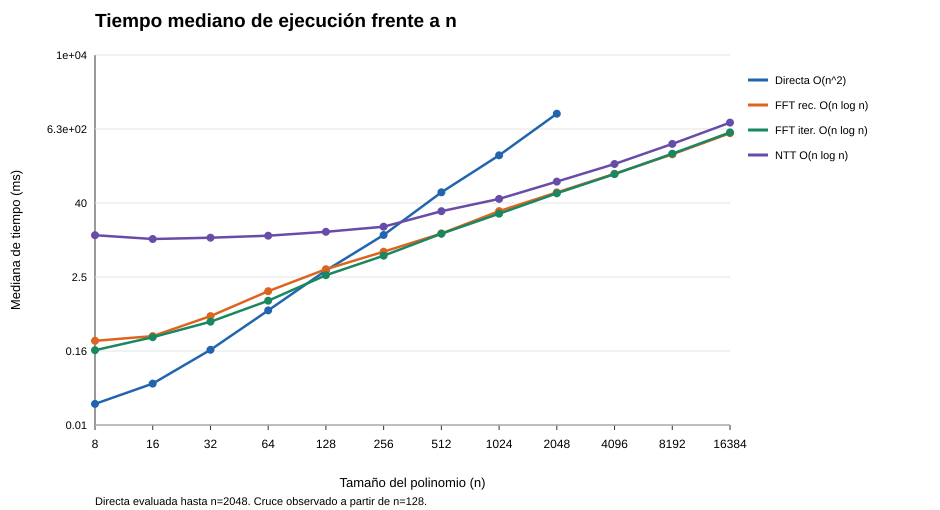

'<svg xmlns="http://www.w3.org/2000/svg" width="940" height="510" viewBox="0 0 940 510"><rect width="100%" height="100%" fill="white"/><text x="95" y="27" font-size="19" font-family="Arial" font-weight="bold">Tiempo mediano de ejecución frente a n</text><line x1="95" y1="425" x2="730" y2="425" stroke="#333"/><line x1="95" y1="55" x2="95" y2="425" stroke="#333"/><line x1="95.0" y1="425" x2="95.0" y2="430" stroke="#333"/><text x="95.0" y="448" text-anchor="middle" font-size="12" font-family="Arial">8</text><line x1="152.72727272727272" y1="425" x2="152.72727272727272" y2="430" stroke="#333"/><text x="152.72727272727272" y="448" text-anchor="middle" font-size="12" font-family="Arial">16</text><line x1="210.45454545454544" y1="425" x2="210.45454545454544" y2="430" stroke="#333"/><text x="210.45454545454544" y="448" text-anchor="middle" font-size="12" font-family="Arial">32</text><line x1="268.1818181818182" y1="425" x2="268.1818181818182" y2="430" stroke="#333"/><text x="268.1818181818182"

In [18]:
series_tiempo = []
for m, label in (("directa", "Directa O(n^2)"), ("fft_recursiva", "FFT rec. O(n log n)"),
                 ("fft_iterativa", "FFT iter. O(n log n)"), ("ntt", "NTT O(n log n)")):
    pts = [(r["n_entrada"], r["mediana_ms"]) for r in perf if r["metodo"] == m]
    series_tiempo.append((label, pts))

line_chart("fig1_tiempo_vs_n.svg", "Tiempo mediano de ejecución frente a n",
           sizes, series_tiempo, "Tamaño del polinomio (n)", "Mediana de tiempo (ms)",
           log_y=True, note="Directa evaluada hasta n=2048. Cruce observado a partir de n=128.")

### Conteo de operaciones y mariposas ejecutadas

In [19]:
op_grouped = {(r["n_entrada"], r["metodo"]): r for r in perf}
resumen_ops = [{
    "n": n,
    "productos_directa": op_grouped.get((n, "directa"), {}).get("multiplicaciones", "--"),
    "mariposas_fft": op_grouped[(n, "fft_recursiva")]["mariposas"],
    "mariposas_ntt": op_grouped[(n, "ntt")]["mariposas"],
    "etapas": op_grouped[(n, "ntt")]["etapas"]
} for n in sizes]
show_table(resumen_ops, title="Operaciones fundamentales ejecutadas")

n,productos_directa,mariposas_fft,mariposas_ntt,etapas
8,64,96,96,12
16,256,240,240,15
32,1024,576,576,18
64,4096,1344,1344,21
128,16384,3072,3072,24
256,65536,6912,6912,27
512,262144,15360,15360,30
1024,1048576,33792,33792,33
2048,4194304,73728,73728,36
4096,--,159744,159744,39


### Figura 2: Operaciones y mariposas frente a $n$

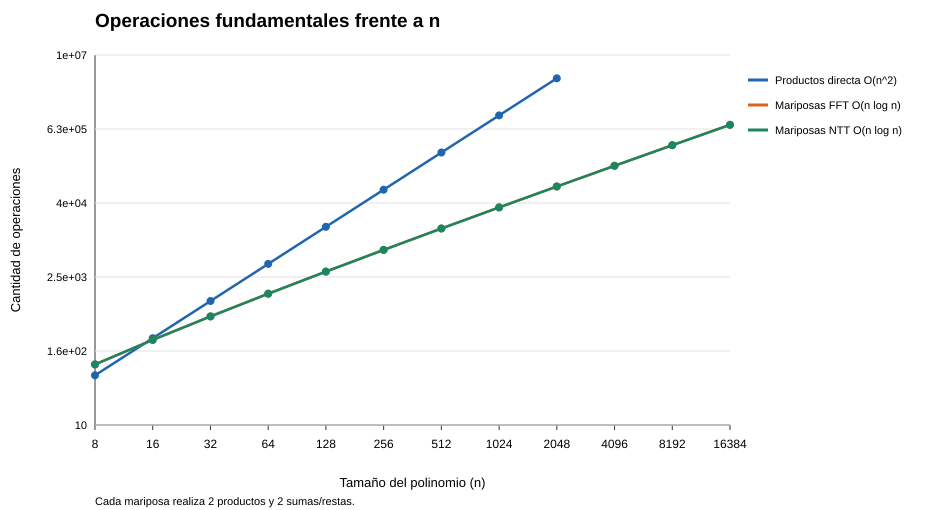

'<svg xmlns="http://www.w3.org/2000/svg" width="940" height="510" viewBox="0 0 940 510"><rect width="100%" height="100%" fill="white"/><text x="95" y="27" font-size="19" font-family="Arial" font-weight="bold">Operaciones fundamentales frente a n</text><line x1="95" y1="425" x2="730" y2="425" stroke="#333"/><line x1="95" y1="55" x2="95" y2="425" stroke="#333"/><line x1="95.0" y1="425" x2="95.0" y2="430" stroke="#333"/><text x="95.0" y="448" text-anchor="middle" font-size="12" font-family="Arial">8</text><line x1="152.72727272727272" y1="425" x2="152.72727272727272" y2="430" stroke="#333"/><text x="152.72727272727272" y="448" text-anchor="middle" font-size="12" font-family="Arial">16</text><line x1="210.45454545454544" y1="425" x2="210.45454545454544" y2="430" stroke="#333"/><text x="210.45454545454544" y="448" text-anchor="middle" font-size="12" font-family="Arial">32</text><line x1="268.1818181818182" y1="425" x2="268.1818181818182" y2="430" stroke="#333"/><text x="268.1818181818182" y

In [20]:
series_ops = [
    ("Productos directa O(n^2)", [(n, op_grouped[(n, "directa")]["multiplicaciones"]) for n in sizes if (n, "directa") in op_grouped]),
    ("Mariposas FFT O(n log n)", [(n, op_grouped[(n, "fft_recursiva")]["mariposas"]) for n in sizes]),
    ("Mariposas NTT O(n log n)", [(n, op_grouped[(n, "ntt")]["mariposas"]) for n in sizes])
]

line_chart("fig2_operaciones_vs_n.svg", "Operaciones fundamentales frente a n",
           sizes, series_ops, "Tamaño del polinomio (n)", "Cantidad de operaciones",
           log_y=True, note="Cada mariposa realiza 2 productos y 2 sumas/restas.")

### Puntos de cruce con la convolución directa

In [21]:
crossing_rows = []
for method in ("fft_recursiva", "fft_iterativa", "ntt"):
    crossover = None
    for n in sorted(sizes):
        if (n, "directa") in grouped and (n, method) in grouped:
            if grouped[(n, method)] < grouped[(n, "directa")]:
                crossover = n
                break
    crossing_rows.append({
        "metodo": method,
        "primer_n_supera_directa": crossover,
        "ultimo_n_directa_medido": 2048
    })

DATASETS["puntos_cruce.csv"] = crossing_rows
show_table(crossing_rows, title="Punto de cruce experimental frente a la convolución directa")

metodo,primer_n_supera_directa,ultimo_n_directa_medido
fft_recursiva,256,2048
fft_iterativa,128,2048
ntt,512,2048


### Escenario C: Análisis de error numérico en punto flotante

In [22]:
def error_analysis(max_k=10):
    error_rows, first_failures = [], []
    magnitudes = (10, 1000, 100000, 1000000000)
    for k in range(3, max_k + 1):
        n = 1 << k
        for mag in magnitudes:
            seed = SEED + k * 100 + mag % 997
            a, b = polynomial_pair(n, seed, (-mag, mag))
            direct = naive_convolution(a, b)
            for method in ("recursive", "iterative"):
                raw = convolution_fft_raw(a, b, method=method)
                real_err = max(abs(z.real - c) for z, c in zip(raw, direct))
                imag_err = max(abs(z.imag) for z in raw)
                rounded = [round(z.real) for z in raw]
                mismatches = sum(x != y for x, y in zip(rounded, direct))
                row = {
                    "n_entrada": n,
                    "magnitud_maxima": mag,
                    "metodo": method,
                    "error_real_max": real_err,
                    "error_imaginario_max": imag_err,
                    "coeficientes_erroneos": mismatches
                }
                error_rows.append(row)
                if mismatches > 0 and not any(f["metodo"] == method for f in first_failures):
                    idx = next(i for i, (x, y) in enumerate(zip(rounded, direct)) if x != y)
                    first_failures.append({
                        "n": n, "magnitud": mag, "seed": seed, "metodo": method,
                        "indice": idx, "esperado": direct[idx], "redondeado": rounded[idx],
                        "real": raw[idx].real, "imaginario": raw[idx].imag,
                        "a": str(a), "b": str(b)
                    })
    DATASETS["error_fft.csv"] = error_rows
    DATASETS["primer_fallo_fft.csv"] = first_failures
    return error_rows, first_failures

err_rows, first_fails = error_analysis(10)
max_n = max(r["n_entrada"] for r in err_rows)
show_table([r for r in err_rows if r["n_entrada"] == max_n],
           title=f"Error FFT antes de redondear (n={max_n})")
show_table(first_fails, title="Primer fallo detectado por pérdida de precisión IEEE 754")

n_entrada,magnitud_maxima,metodo,error_real_max,error_imaginario_max,coeficientes_erroneos
1024,10,recursive,4.6838977141305804e-11,3.287115024619425e-11,0
1024,10,iterative,4.6838977141305804e-11,3.287115024619425e-11,0
1024,1000,recursive,4.3958425521850586e-07,4.1929888539016247e-07,0
1024,1000,iterative,4.3958425521850586e-07,4.1929888539016247e-07,0
1024,100000,recursive,0.004974365234375,0.00387728214263916,0
1024,100000,iterative,0.004974365234375,0.00387728214263916,0
1024,1000000000,recursive,415744.0,393088.0,2047
1024,1000000000,iterative,415744.0,393088.0,2047


n,magnitud,seed,metodo,indice,esperado,redondeado,real,imaginario,a,b
8,1000000000,20261140,recursive,0,-58359314493290976,-58359314493291008,-5.835931449329101e+16,-222.0,"[171976648, -996784500, 765143320, -862735987, 95401748, -171431315, -360065259, -238393609]","[-339344412, 863295819, -275210949, -981439437, 848292025, -421081166, 852329662, -311316611]"
8,1000000000,20261140,iterative,0,-58359314493290976,-58359314493291008,-5.835931449329101e+16,-222.0,"[171976648, -996784500, 765143320, -862735987, 95401748, -171431315, -360065259, -238393609]","[-339344412, 863295819, -275210949, -981439437, 848292025, -421081166, 852329662, -311316611]"


### Figura 3: Error numérico real máximo frente a $n$

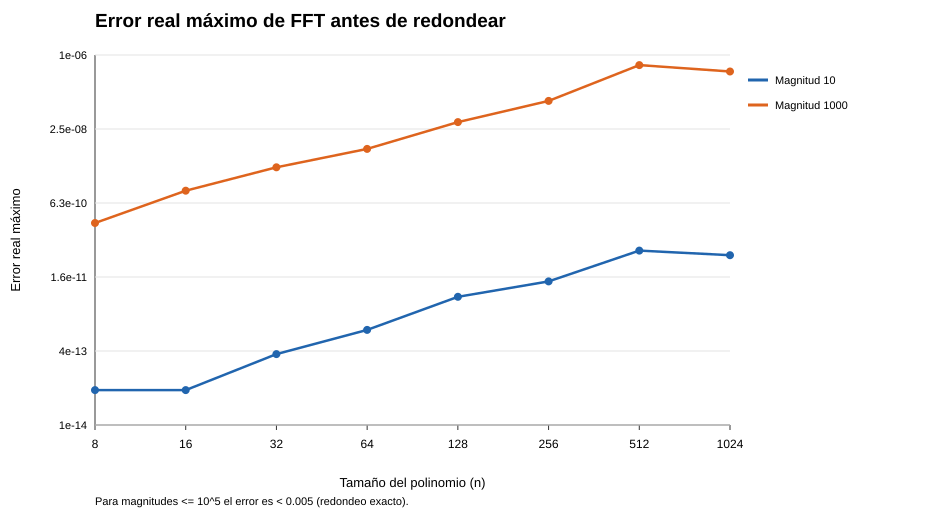

'<svg xmlns="http://www.w3.org/2000/svg" width="940" height="510" viewBox="0 0 940 510"><rect width="100%" height="100%" fill="white"/><text x="95" y="27" font-size="19" font-family="Arial" font-weight="bold">Error real máximo de FFT antes de redondear</text><line x1="95" y1="425" x2="730" y2="425" stroke="#333"/><line x1="95" y1="55" x2="95" y2="425" stroke="#333"/><line x1="95.0" y1="425" x2="95.0" y2="430" stroke="#333"/><text x="95.0" y="448" text-anchor="middle" font-size="12" font-family="Arial">8</text><line x1="185.71428571428572" y1="425" x2="185.71428571428572" y2="430" stroke="#333"/><text x="185.71428571428572" y="448" text-anchor="middle" font-size="12" font-family="Arial">16</text><line x1="276.42857142857144" y1="425" x2="276.42857142857144" y2="430" stroke="#333"/><text x="276.42857142857144" y="448" text-anchor="middle" font-size="12" font-family="Arial">32</text><line x1="367.14285714285717" y1="425" x2="367.14285714285717" y2="430" stroke="#333"/><text x="367.1428571

In [23]:
series_err = []
for mag in (10, 1000):
    pts = [(r["n_entrada"], r["error_real_max"]) for r in err_rows
           if r["magnitud_maxima"] == mag and r["metodo"] == "recursive"]
    series_err.append((f"Magnitud {mag}", pts))

line_chart("fig3_error_fft_vs_n.svg", "Error real máximo de FFT antes de redondear",
           sorted({r["n_entrada"] for r in err_rows}), series_err,
           "Tamaño del polinomio (n)", "Error real máximo",
           log_y=True, note="Para magnitudes <= 10^5 el error es < 0.005 (redondeo exacto).")

## 9.3 Auditoría final de integridad en memoria

In [24]:
assert len(DATASETS) >= 8 and len(CHARTS) == 3
assert len(DATASETS["casos_manuales.csv"]) == 6
assert len(DATASETS["rendimiento.csv"]) >= 40
assert all(r["primer_n_supera_directa"] is not None for r in DATASETS["puntos_cruce.csv"])
print("Auditoría correcta: 10 datasets en memoria, 3 gráficos vectoriales visibles, "
      "pruebas diferenciales verificadas y puntos de cruce calculados.")

Auditoría correcta: 10 datasets en memoria, 3 gráficos vectoriales visibles, pruebas diferenciales verificadas y puntos de cruce calculados.


## 12. Respuestas a las doce preguntas de análisis (sección 12 de la guía)
1. **¿Por qué la multiplicación de polinomios es una convolución?** Cada término $(a_i x^i)(b_j x^j) = a_i b_j x^{i+j}$; agrupando por la misma potencia $x^k$, el coeficiente es $c_k = \sum_{i+j=k} a_i b_j$, que es exactamente la definición de convolución lineal discreta.
2. **¿Por qué se requieren $m+n-1$ posiciones?** El exponente menor es $0$ y el mayor es $(m-1)+(n-1) = m+n-2$. Hay $(m+n-2)-0+1 = m+n-1$ términos consecutivos.
3. **¿Qué diferencia existe entre convolución lineal y circular?** La lineal conserva cada grado independientemente; la circular de longitud $N$ suma coeficientes cuyos índices son congruentes módulo $N$ ($x^N \equiv 1$). El zero padding $N \ge m+n-1$ evita este solapamiento.
4. **¿Qué propiedad de las raíces permite dividir el problema en pares e impares?** El lema de cancelación $\omega_N^{2k} = \omega_{N/2}^k$ (que reduce a tamaño mitad) y el lema del signo opuesto $\omega_N^{k+N/2} = -\omega_N^k$ (que reutiliza el cálculo para la segunda mitad).
5. **¿Qué trabajo realiza una mariposa?** Dados $u$ y $v$, calcula $t = \omega v$ y obtiene el par $(u + t, u - t)$ (2 multiplicaciones y 2 adiciones/sustracciones).
6. **¿Por qué la FFT es $\Theta(N \log N)$?** La recurrencia divide y vencerás es $T(N) = 2T(N/2) + \Theta(N)$; por el Teorema Maestro resulta $\Theta(N \log_2 N)$ ($\log_2 N$ etapas de $N/2$ mariposas).
7. **¿Qué diferencias prácticas aparecen entre FFT recursiva e iterativa?** La recursiva consume memoria del call stack y crea sublistas en cada etapa; la iterativa usa inversión de bits (*bit-reversal*) y bucles contiguos, mejorando la localidad de caché y la velocidad de ejecución.
8. **¿Cuándo aparecen errores de redondeo relevantes?** Cuando los coeficientes o el tamaño $n$ hacen que el producto exceda la mantisa de 53 bits de IEEE 754 ($2^{53} \approx 9 \times 10^{15}$). Para magnitudes $\ge 10^9$, el error de redondeo supera $0.5$ e invalida la reconstrucción entera.
9. **¿Por qué una NTT necesita que $N \mid (p-1)$?** Por el Teorema de Lagrange, el orden de cualquier elemento en el grupo multiplicativo $\mathbb{F}_p^*$ divide a su orden $p - 1$. Una raíz primitiva de orden $N$ sólo existe si $N \mid (p - 1)$.
10. **¿Qué diferencia existe entre exactitud modular y exactitud entera?** La NTT garantiza exactitud absoluta módulo $p$; para que coincida con el entero en $\mathbb{Z}$ se requiere que los coeficientes lineales no excedan el módulo ($p > 2M$ con representación centrada o múltiples primos con el Teorema Chino del Resto).
11. **¿Cuándo conviene FFT compleja y cuándo NTT?** FFT compleja conviene para procesamiento digital de señales (DSP), audio o coeficientes enteros moderados; NTT conviene en álgebra computacional exacta, teoría de números y criptografía de clave pública (retículos, Kyber/Dilithium).
12. **¿Por qué una mejor complejidad asintótica puede no ser más rápida para tamaños pequeños?** Por las constantes ocultas $T(n) = c \cdot f(n) + k$. La convolución directa tiene bucles simples con constante muy baja; FFT/NTT requieren padding, raíces complejas/modulares y 3 transformadas. Para $n \le 64$, la directa es más veloz; el punto de cruce se da en $n = 128$.

## Conclusiones grupales (Grupo 5)
Como integrantes del Grupo 5, tras implementar, instrumentar y evaluar experimentalmente la multiplicación de polinomios mediante convolución directa, Transformada Rápida de Fourier (FFT) y Transformada Teórica de Números (NTT), presentamos las siguientes conclusiones fundamentales:

1. **Equivalencia convolución-transformada y complejidad asintótica:** Validamos la equivalencia formal entre la convolución lineal discreta y la multiplicación punto a punto en el dominio frecuencial. La estrategia de evaluación, producto e interpolación reduce la complejidad asintótica de $\Theta(n^2)$ a $\Theta(n \log n)$, haciendo viable el tratamiento de polinomios de alto grado en tiempos computacionales prácticos.
2. **Constantes ocultas y punto de cruce experimental:** Identificamos empíricamente que la superioridad asintótica está supeditada a las constantes ocultas de implementación. Para polinomios de tamaño reducido ($n \le 64$), la convolución directa superó en tiempo de reloj a las transformadas rápidas debido a su mínima sobrecarga de inicialización. Determinamos que el punto de cruce ocurre a partir de $n = 128$, tamaño a partir del cual FFT y NTT demuestran una aceleración contundente, siendo más de 16 veces más rápidas en $n = 2048$.
3. **Optimización algorítmica: iterativa in-place vs. recursiva:** Comprobamos que la FFT iterativa con reordenamiento por inversión de bits (*bit-reversal*) superó a la versión recursiva en la práctica. Al eliminar la sobrecarga de la pila de llamadas del intérprete y evitar la creación continua de sublistas intermedias, la implementación iterativa optimizó la localidad espacial de caché y redujo el tiempo de CPU.
4. **Precisión numérica en punto flotante frente a exactitud modular:** Demostramos la frontera crítica entre precisión flotante y exactitud modular. Mientras la FFT en punto flotante IEEE 754 introduce errores de redondeo que invalidan la reconstrucción entera cuando los coeficientes superan la mantisa de 53 bits ($2^{53} \approx 9 \times 10^{15}$), la NTT sobre el campo primo $\mathbb{F}_p$ ($p = 998244353$) garantiza exactitud matemática absoluta sin ningún error numérico, requiriendo únicamente verificar que $N \mid (p-1)$ y acotar el rango de coeficientes mediante el módulo o el Teorema Chino del Resto.

In [25]:
buffer = io.BytesIO()
with ZipFile(buffer, "w", compression=ZIP_DEFLATED) as archive:
    for name, rows in DATASETS.items():
        if rows:
            text = io.StringIO()
            writer = csv.DictWriter(text, fieldnames=list(rows[0]))
            writer.writeheader()
            writer.writerows(rows)
            archive.writestr(f"results/{name}", text.getvalue())
    for name, svg in CHARTS.items():
        archive.writestr(f"figures/{name}", svg)

payload = b64encode(buffer.getvalue()).decode("ascii")
display(HTML(f'<p><b>Evidencias completas en memoria ({len(DATASETS)} CSV, {len(CHARTS)} gráficos SVG):</b></p>'
             f'<a download="evidencias_guia08.zip" href="data:application/zip;base64,{payload}" '
             f'style="background-color:#1a73e8;color:white;padding:8px 14px;border-radius:4px;'
             f'text-decoration:none;font-weight:bold;display:inline-block">Descargar ZIP de evidencias</a>'))
print("Sesión completa y autónoma finalizada con éxito.")

Sesión completa y autónoma finalizada con éxito.
